# Maternal Health Risk Classification using Machine Learning
## Final Analysis Notebook - COM725 Assessment 2

**Dataset:** Maternal Health Risk (1,014 records)  
**Date:** August 2025


## 1. Introduction and Research Aim

### Background
Maternal morbidity and mortality are global health priorities. Machine learning models show strong potential to support triage and decision-making in maternal health.

### Research Aim
To investigate whether routinely collected maternal vital sign data can classify individuals into risk categories using machine learning.

In [1]:
# Import required libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_curve, auc)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load dataset
df = pd.read_csv('../data/maternal_health_risk.csv')

print("="*60)
print("DATASET LOADED")
print("="*60)
print(f"Shape: {df.shape}")
print(f"Records: {df.shape[0]}")
print(f"Features: {df.shape[1]}")
df.head()

DATASET LOADED
Shape: (1014, 7)
Records: 1014
Features: 7


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


## 2. Data Quality Assessment

In [3]:
# Data quality checks
print("="*60)
print("DATA QUALITY ASSESSMENT")
print("="*60)

print("\nDataset Info:")
df.info()

print("\nDescriptive Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
duplicates = df.duplicated().sum()
print(f"Duplicates: {duplicates} ({(duplicates/len(df)*100):.2f}%)")

print("\nTarget Distribution:")
print(df['RiskLevel'].value_counts())

DATA QUALITY ASSESSMENT

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB

Descriptive Statistics:
               Age   SystolicBP  DiastolicBP           BS     BodyTemp  \
count  1014.000000  1014.000000  1014.000000  1014.000000  1014.000000   
mean     29.871795   113.198225    76.460552     8.725986    98.665089   
std      13.474386    18.403913    13.885796     3.293532     1.371384   
min      10.000000    70.000000    49.000000     6.000000    98.000000   
25%      19.000000 

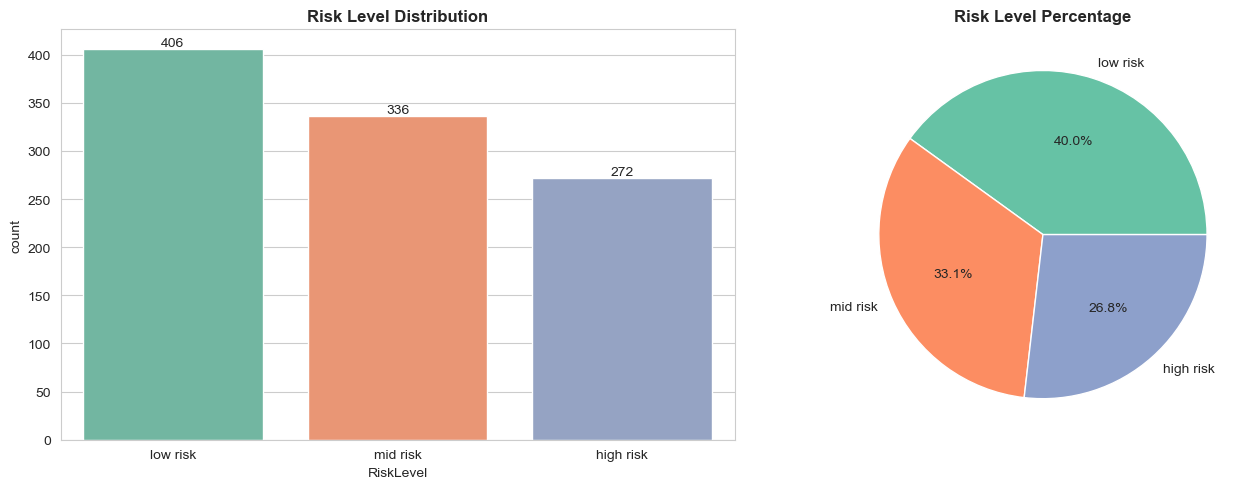

Figure 1 saved!


In [4]:
# Visualize class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

risk_order = ['low risk', 'mid risk', 'high risk']
sns.countplot(data=df, x='RiskLevel', order=risk_order, palette='Set2', ax=axes[0])
axes[0].set_title('Risk Level Distribution', fontweight='bold')
for container in axes[0].containers:
    axes[0].bar_label(container)

df['RiskLevel'].value_counts().plot(kind='pie', ax=axes[1], autopct='%1.1f%%',
                                     colors=sns.color_palette('Set2'))
axes[1].set_title('Risk Level Percentage', fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('../figures/fig1_risk_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 1 saved!")

## 3. Exploratory Data Analysis

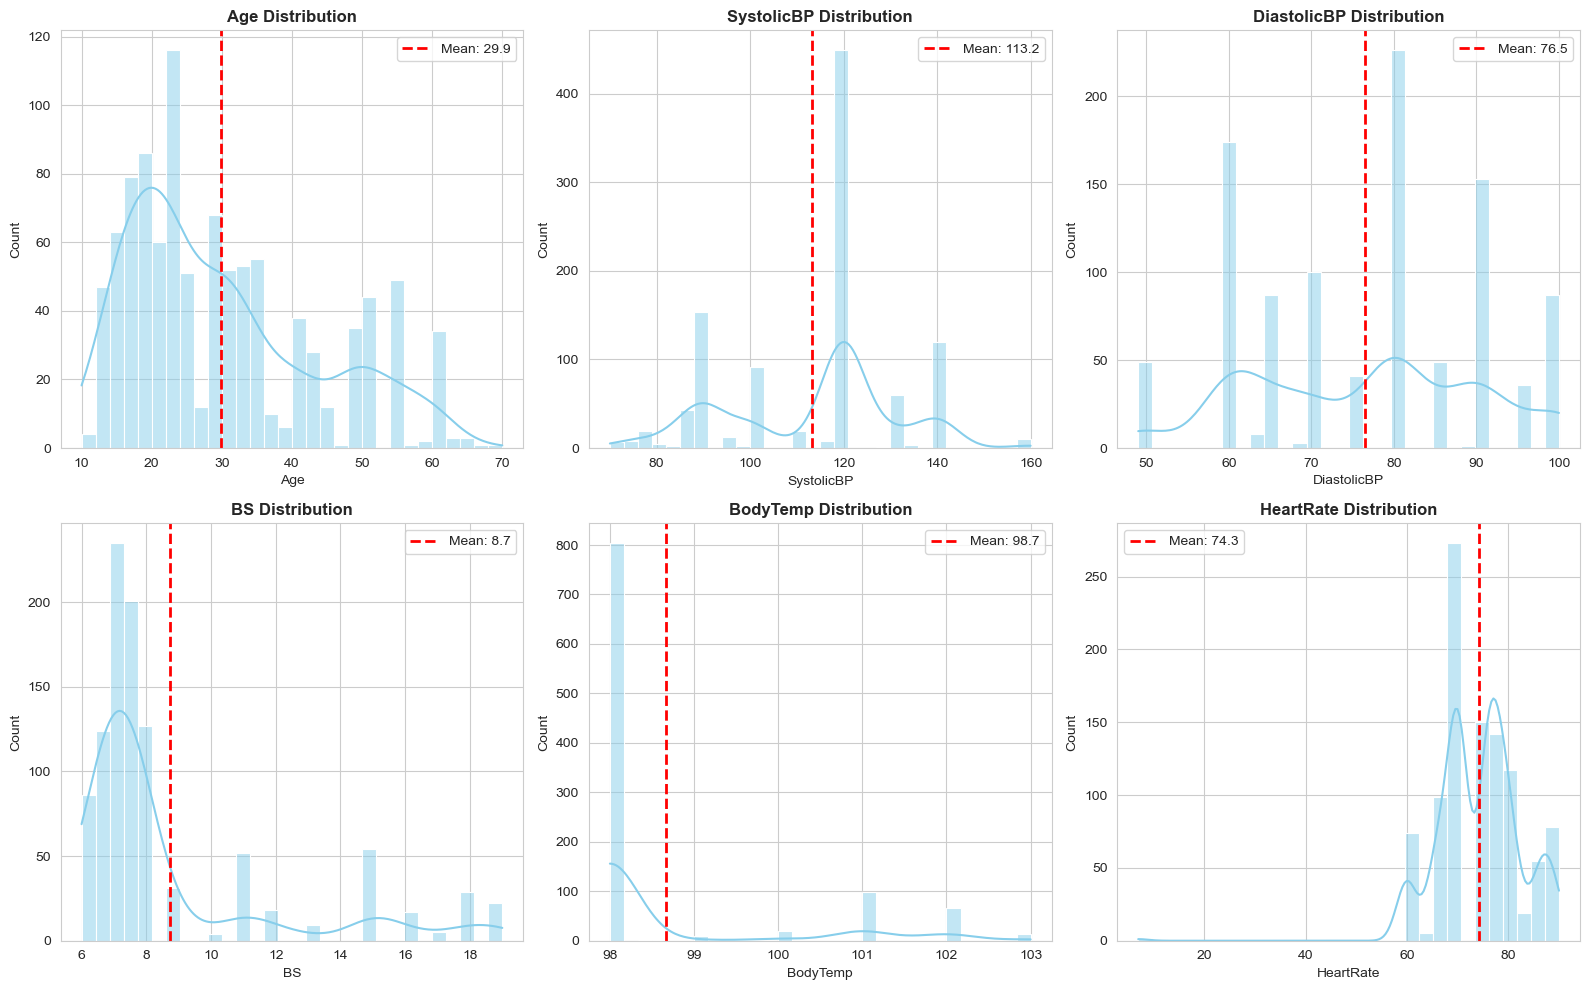

Figure 2 saved!


In [5]:
# Feature distributions
numerical_features = ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for idx, feature in enumerate(numerical_features):
    sns.histplot(data=df, x=feature, kde=True, bins=30, color='skyblue', ax=axes[idx])
    axes[idx].set_title(f'{feature} Distribution', fontweight='bold')
    mean_val = df[feature].mean()
    axes[idx].axvline(mean_val, color='red', linestyle='--', linewidth=2,
                      label=f'Mean: {mean_val:.1f}')
    axes[idx].legend()

plt.tight_layout()
plt.savefig('../figures/fig2_feature_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 2 saved!")

In [6]:
# Distribution statistics
print("="*60)
print("DISTRIBUTION STATISTICS")
print("="*60)

stats_df = pd.DataFrame({
    'Feature': numerical_features,
    'Mean': [df[col].mean() for col in numerical_features],
    'Std': [df[col].std() for col in numerical_features],
    'Skewness': [df[col].skew() for col in numerical_features],
    'Kurtosis': [df[col].kurtosis() for col in numerical_features]
})

print(stats_df)

DISTRIBUTION STATISTICS
       Feature        Mean        Std  Skewness  Kurtosis
0          Age   29.871795  13.474386  0.783063 -0.391414
1   SystolicBP  113.198225  18.403913 -0.251189 -0.613382
2  DiastolicBP   76.460552  13.885796 -0.048441 -0.948634
3           BS    8.725986   3.293532  1.868203  2.303174
4     BodyTemp   98.665089   1.371384  1.750988  1.451680
5    HeartRate   74.301775   8.088702 -1.043525  8.398871


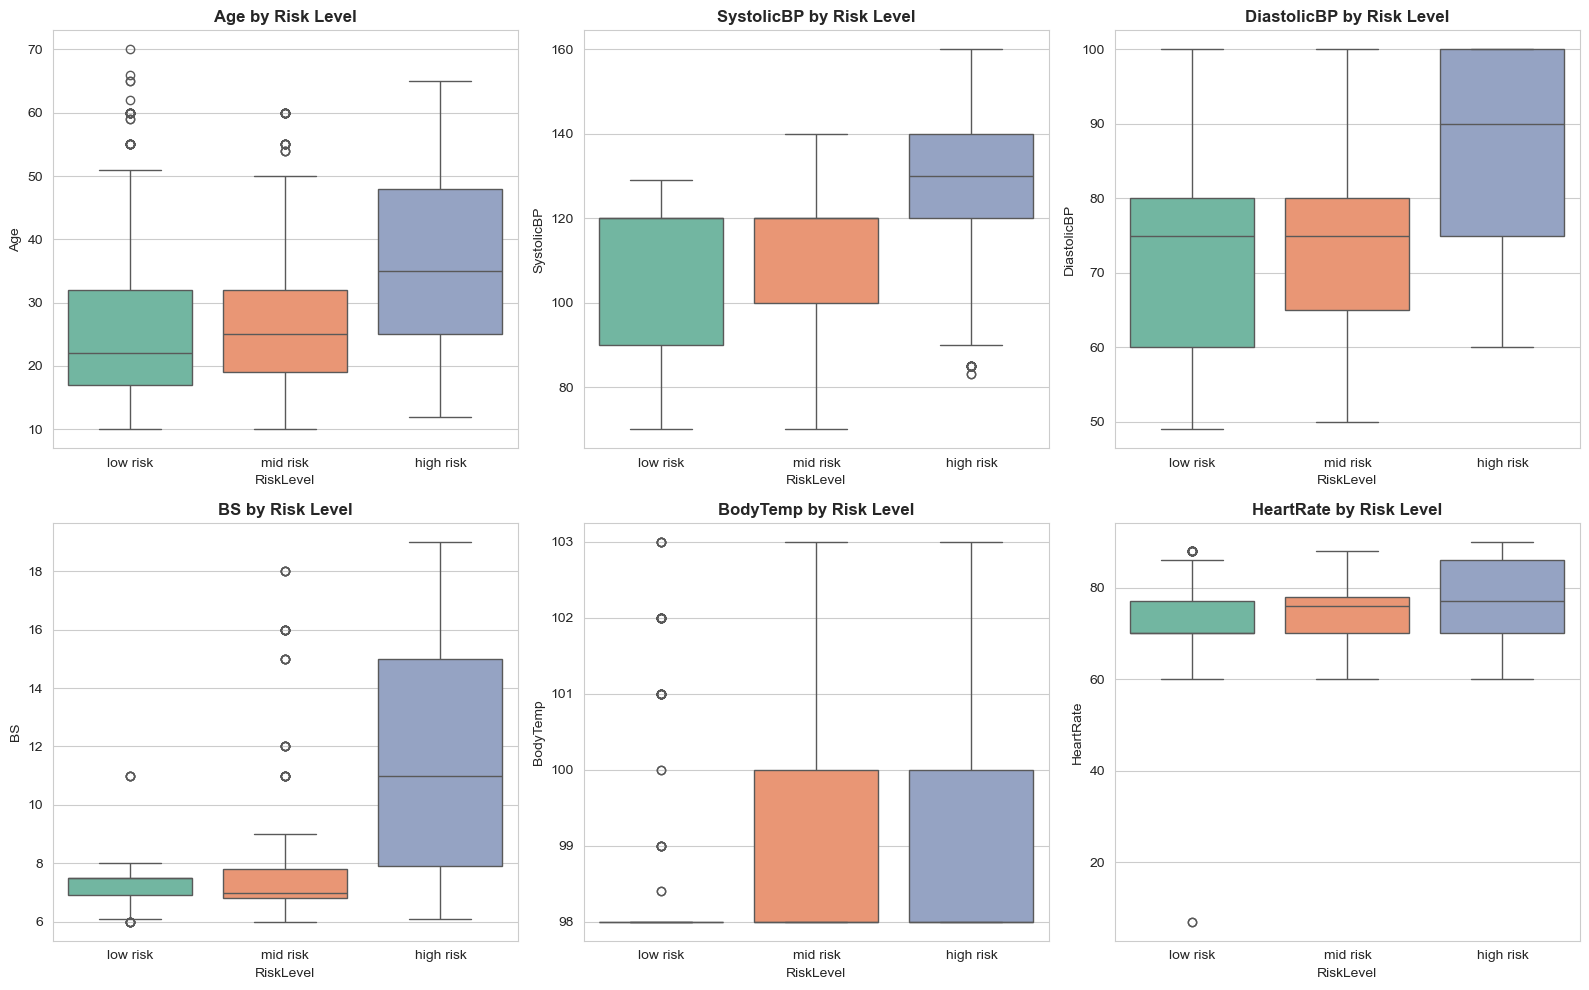

Figure 3 saved!


In [7]:
# Box plots by risk level
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for idx, feature in enumerate(numerical_features):
    sns.boxplot(data=df, x='RiskLevel', y=feature, order=risk_order,
                palette='Set2', ax=axes[idx])
    axes[idx].set_title(f'{feature} by Risk Level', fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/fig3_boxplots_by_risk.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 3 saved!")

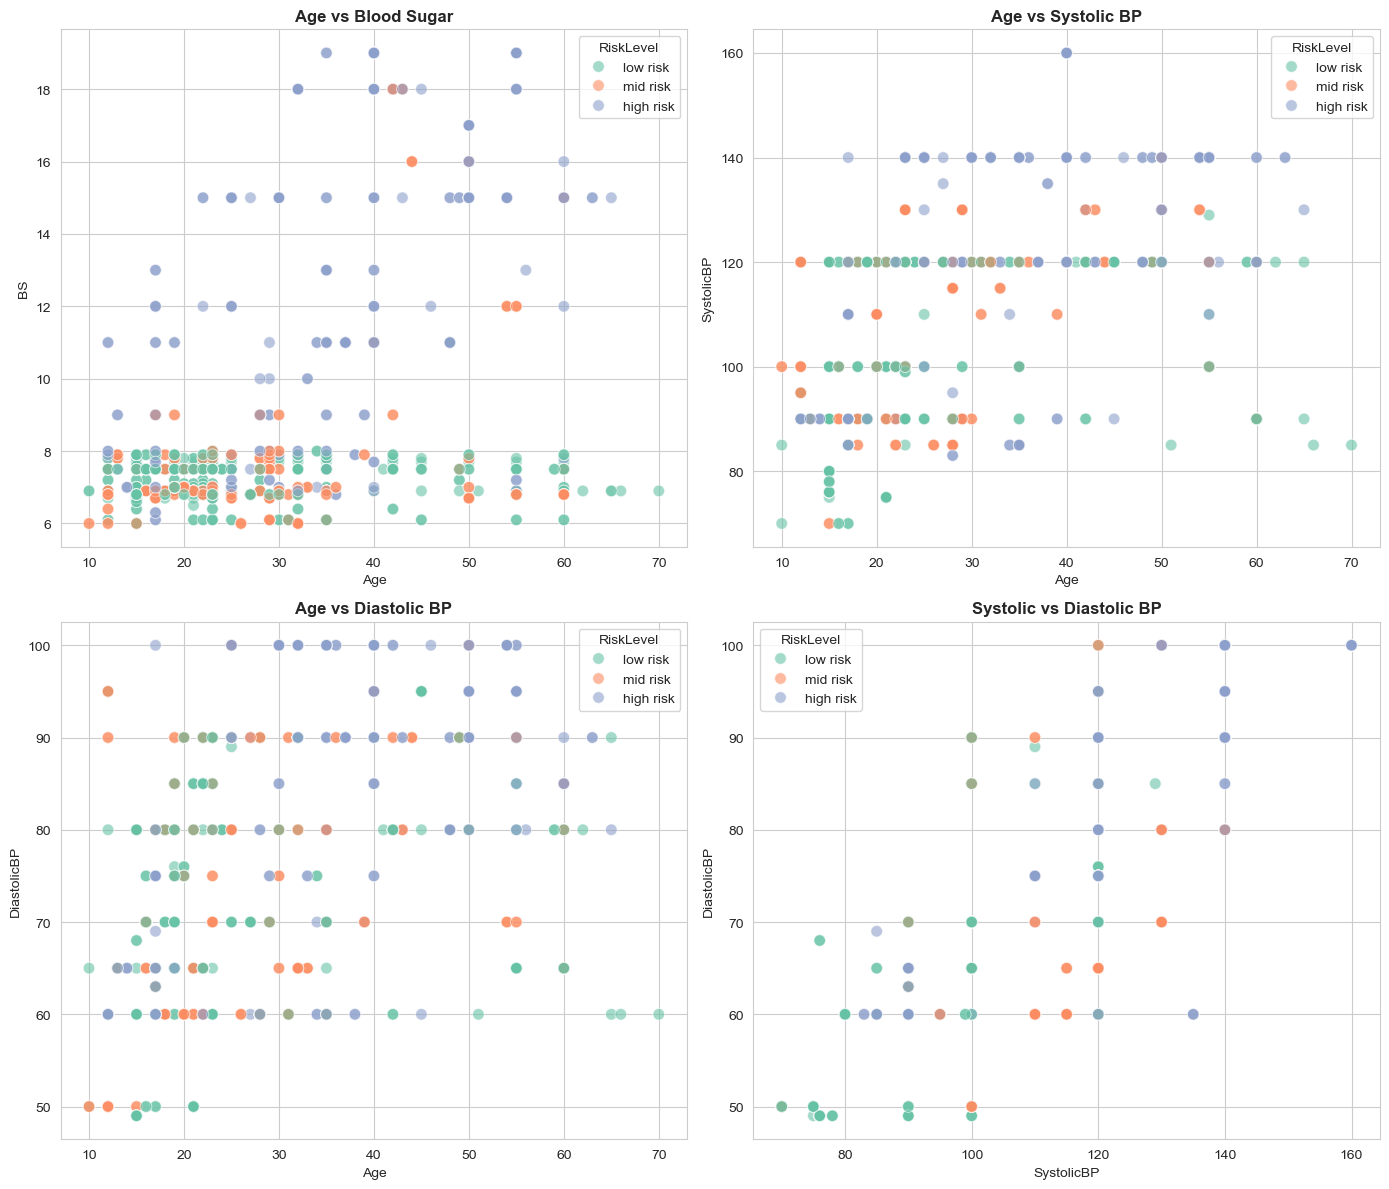

Figure 4 saved!


In [8]:
# Scatter plots
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

sns.scatterplot(data=df, x='Age', y='BS', hue='RiskLevel', hue_order=risk_order,
                palette='Set2', s=70, alpha=0.6, ax=axes[0,0])
axes[0,0].set_title('Age vs Blood Sugar', fontweight='bold')

sns.scatterplot(data=df, x='Age', y='SystolicBP', hue='RiskLevel',
                hue_order=risk_order, palette='Set2', s=70, alpha=0.6, ax=axes[0,1])
axes[0,1].set_title('Age vs Systolic BP', fontweight='bold')

sns.scatterplot(data=df, x='Age', y='DiastolicBP', hue='RiskLevel',
                hue_order=risk_order, palette='Set2', s=70, alpha=0.6, ax=axes[1,0])
axes[1,0].set_title('Age vs Diastolic BP', fontweight='bold')

sns.scatterplot(data=df, x='SystolicBP', y='DiastolicBP', hue='RiskLevel',
                hue_order=risk_order, palette='Set2', s=70, alpha=0.6, ax=axes[1,1])
axes[1,1].set_title('Systolic vs Diastolic BP', fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/fig4_scatter_relationships.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 4 saved!")

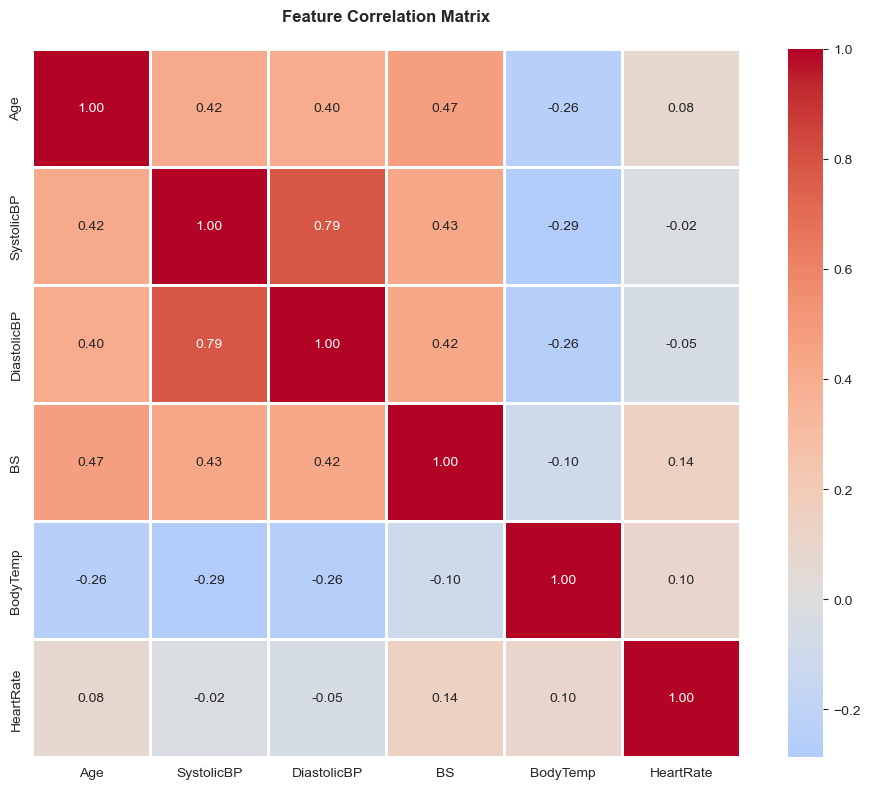

Figure 5 saved!


In [9]:
# Correlation matrix
correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1, fmt='.2f')
plt.title('Feature Correlation Matrix', fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('../figures/fig5_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 5 saved!")

## 4. Data Preparation

In [10]:
# Encode and split
le = LabelEncoder()
df['RiskLevel_encoded'] = le.fit_transform(df['RiskLevel'])

print("Target Encoding:")
for original, encoded in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {original} -> {encoded}")

X = df[numerical_features].copy()
y = df['RiskLevel_encoded'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain size: {X_train.shape[0]}")
print(f"Test size: {X_test.shape[0]}")

Target Encoding:
  high risk -> 0
  low risk -> 1
  mid risk -> 2

Train size: 811
Test size: 203


## 5. Baseline Model

In [11]:
# Train baseline
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_baseline.fit(X_train, y_train)
y_pred_baseline = rf_baseline.predict(X_test)
y_pred_proba_baseline = rf_baseline.predict_proba(X_test)

accuracy = accuracy_score(y_test, y_pred_baseline)
print(f"Baseline Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline, target_names=le.classes_))

Baseline Accuracy: 0.8719

Classification Report:
              precision    recall  f1-score   support

   high risk       0.96      0.95      0.95        55
    low risk       0.89      0.83      0.86        81
    mid risk       0.78      0.87      0.82        67

    accuracy                           0.87       203
   macro avg       0.88      0.88      0.88       203
weighted avg       0.88      0.87      0.87       203



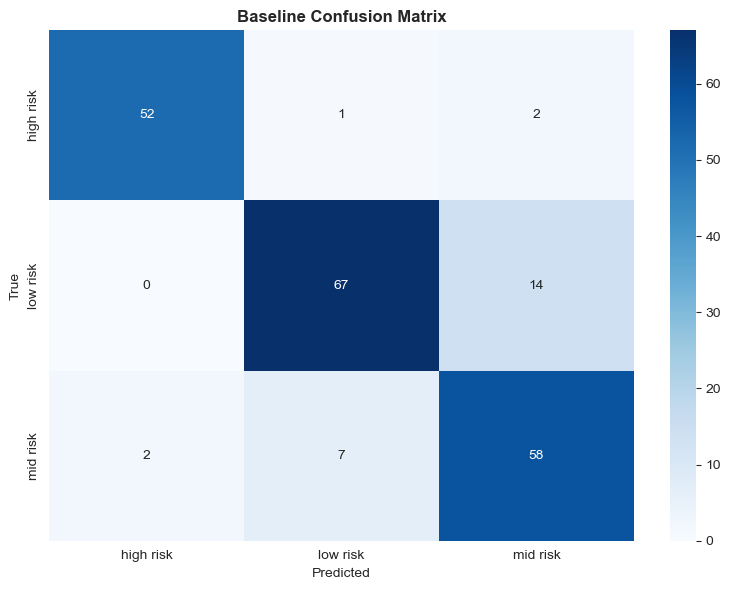

Figure 6 saved!


In [12]:
# Baseline confusion matrix
cm_baseline = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_baseline, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Baseline Confusion Matrix', fontweight='bold')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('../figures/fig6_baseline_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 6 saved!")

In [13]:
# Cross-validation
cv_scores = cross_val_score(rf_baseline, X_train, y_train, cv=5, scoring='accuracy')
print(f"CV Scores: {cv_scores}")
print(f"Mean: {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")

CV Scores: [0.80981595 0.82716049 0.83950617 0.80246914 0.85185185]
Mean: 0.8262 (+/- 0.0365)


## 6. Hyperparameter Optimization

In [14]:
# Randomized search
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 20, 30],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

rf_random = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    random_state=42,
    n_jobs=-1
)

print("Running randomized search...")
rf_random.fit(X_train, y_train)
print(f"Best CV: {rf_random.best_score_:.4f}")
print(f"Best params: {rf_random.best_params_}")

Running randomized search...
Best CV: 0.8274
Best params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}


In [15]:
# Grid search
param_grid = {
    'n_estimators': [200, 300],
    'max_depth': [None, 30],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid=param_grid,
    cv=5,
    n_jobs=-1
)

print("Running grid search...")
rf_grid.fit(X_train, y_train)

rf_tuned = rf_grid.best_estimator_
y_pred_tuned = rf_tuned.predict(X_test)
y_pred_proba_tuned = rf_tuned.predict_proba(X_test)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
print(f"\nTuned Accuracy: {accuracy_tuned:.4f}")

Running grid search...

Tuned Accuracy: 0.8670


## 7. Model Calibration

In [16]:
# Calibrate model
rf_calibrated = CalibratedClassifierCV(rf_tuned, method='isotonic', cv=5)
rf_calibrated.fit(X_train, y_train)

y_pred_calibrated = rf_calibrated.predict(X_test)
y_pred_proba_calibrated = rf_calibrated.predict_proba(X_test)

accuracy_calibrated = accuracy_score(y_test, y_pred_calibrated)
print(f"Calibrated Accuracy: {accuracy_calibrated:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_calibrated, target_names=le.classes_))

Calibrated Accuracy: 0.8670

Classification Report:
              precision    recall  f1-score   support

   high risk       0.96      0.95      0.95        55
    low risk       0.86      0.85      0.86        81
    mid risk       0.80      0.82      0.81        67

    accuracy                           0.87       203
   macro avg       0.87      0.87      0.87       203
weighted avg       0.87      0.87      0.87       203



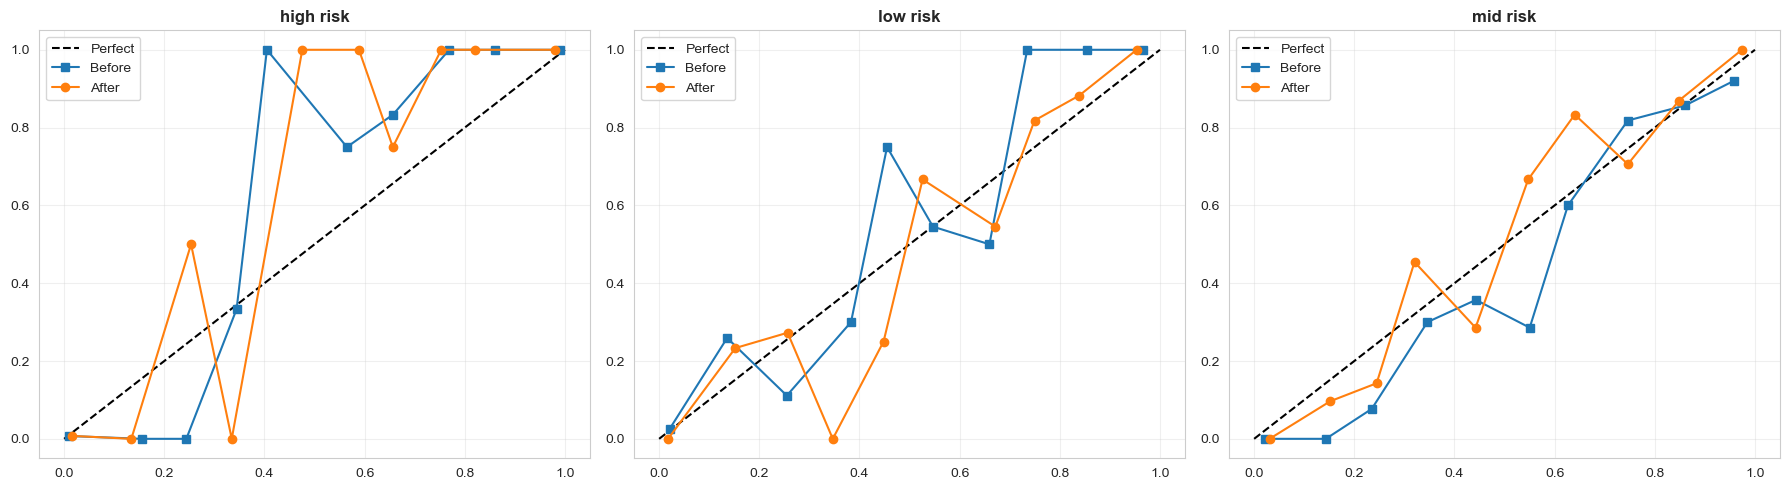

Figure 7 saved!


In [17]:
# Calibration curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, class_name in enumerate(le.classes_):
    frac_pos_t, mean_pred_t = calibration_curve(
        (y_test == idx).astype(int), y_pred_proba_tuned[:, idx], n_bins=10)
    frac_pos_c, mean_pred_c = calibration_curve(
        (y_test == idx).astype(int), y_pred_proba_calibrated[:, idx], n_bins=10)
    
    axes[idx].plot([0, 1], [0, 1], 'k--', label='Perfect')
    axes[idx].plot(mean_pred_t, frac_pos_t, 's-', label='Before')
    axes[idx].plot(mean_pred_c, frac_pos_c, 'o-', label='After')
    axes[idx].set_title(f'{class_name}', fontweight='bold')
    axes[idx].legend()
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/fig7_calibration_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 7 saved!")

## 8. Comprehensive Evaluation

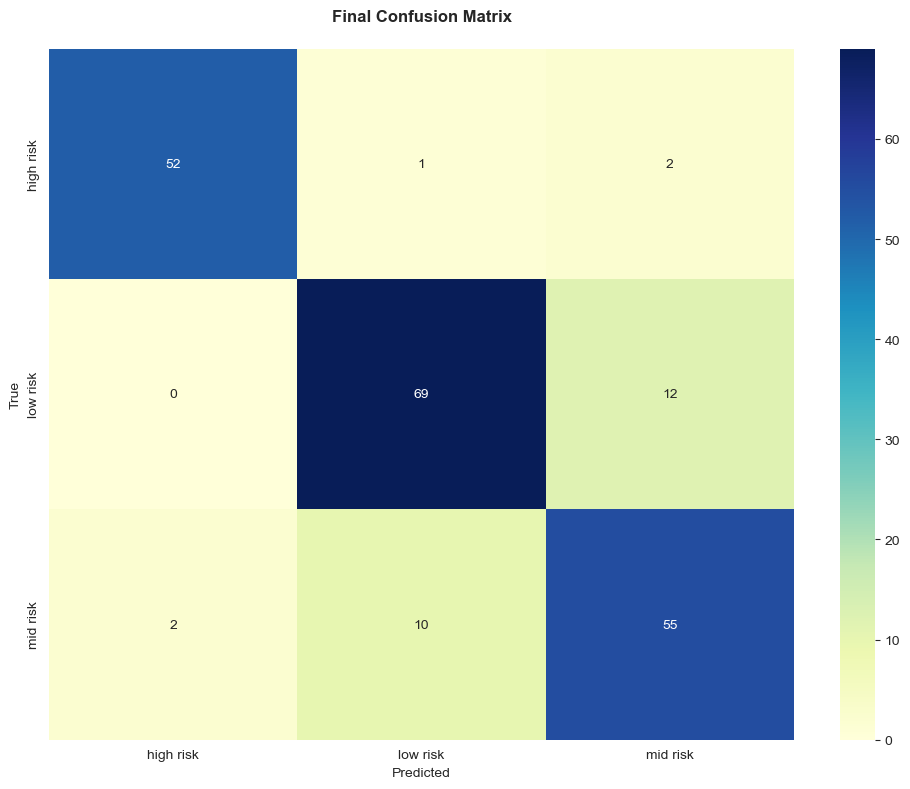

Figure 8 saved!


In [18]:
# Final confusion matrix
cm_final = confusion_matrix(y_test, y_pred_calibrated)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Final Confusion Matrix', fontweight='bold', pad=20)
plt.ylabel('True')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('../figures/fig8_final_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 8 saved!")

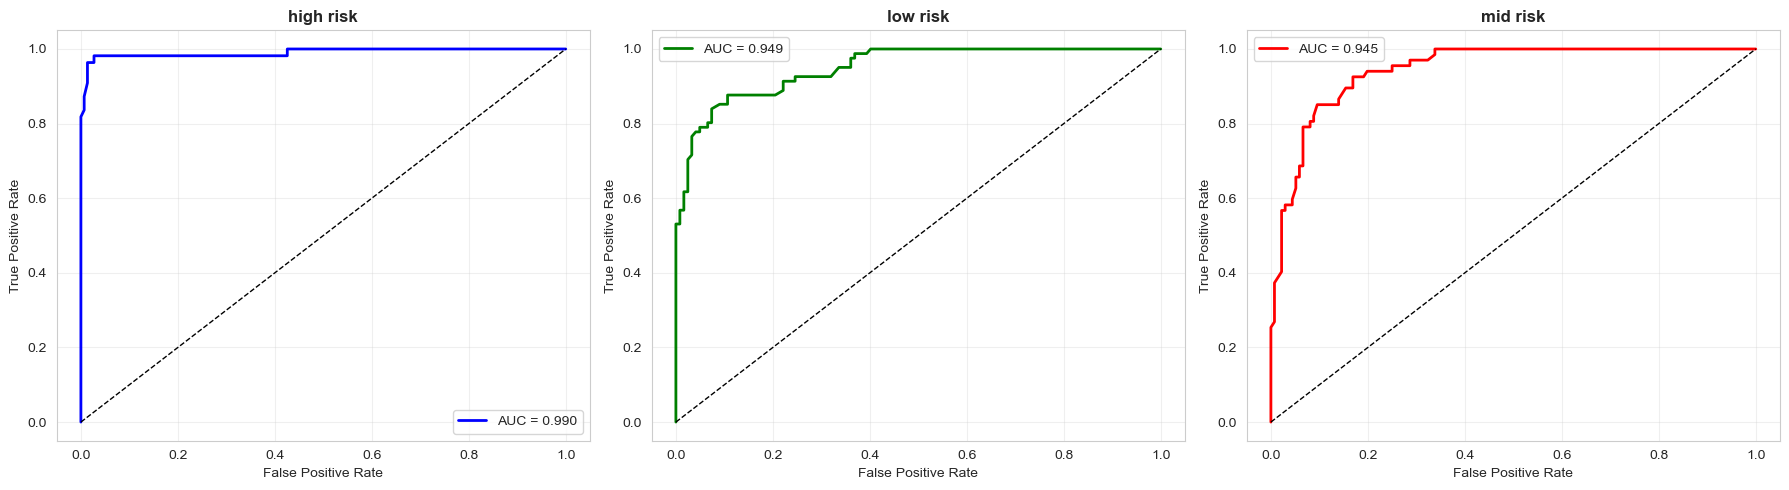

Figure 9 saved!


In [19]:
# ROC curves
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['blue', 'green', 'red']

for i, (class_name, color) in enumerate(zip(le.classes_, colors)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_proba_calibrated[:, i])
    roc_auc = auc(fpr, tpr)
    
    axes[i].plot(fpr, tpr, color=color, lw=2, label=f'AUC = {roc_auc:.3f}')
    axes[i].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[i].set_title(f'{class_name}', fontweight='bold')
    axes[i].set_xlabel('False Positive Rate')
    axes[i].set_ylabel('True Positive Rate')
    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/fig9_roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 9 saved!")

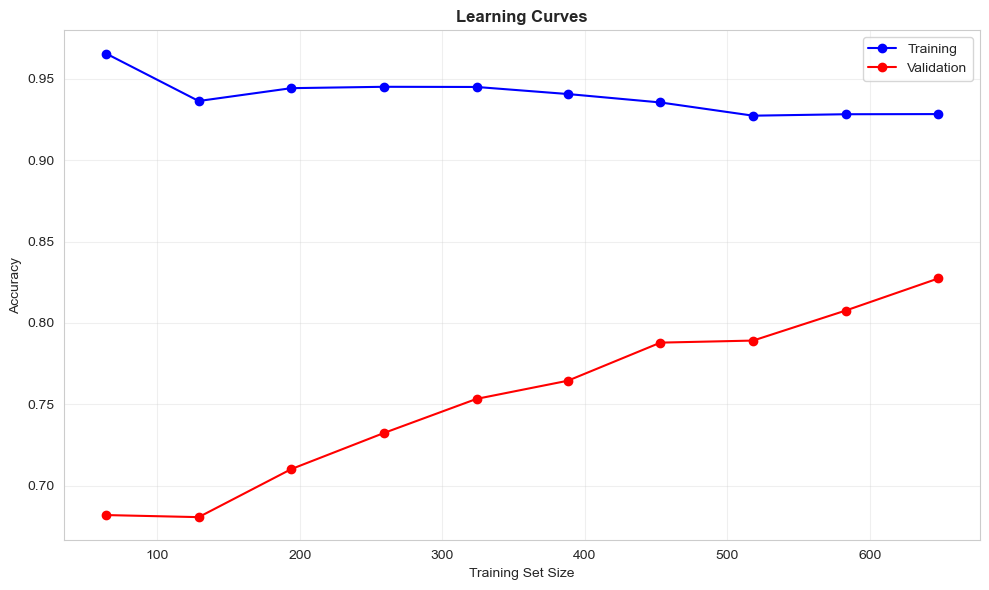

Figure 10 saved!


In [20]:
# Learning curves
train_sizes, train_scores, val_scores = learning_curve(
    rf_tuned, X_train, y_train, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10), random_state=42
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training')
plt.plot(train_sizes, val_mean, 'o-', color='red', label='Validation')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curves', fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/fig10_learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 10 saved!")

## 9. Feature Importance

In [21]:
# Permutation importance
perm_importance = permutation_importance(
    rf_calibrated, X_test, y_test, n_repeats=30, random_state=42
)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': perm_importance.importances_mean,
    'Std': perm_importance.importances_std
}).sort_values('Importance', ascending=False)

print("Feature Importance:")
print(importance_df)

Feature Importance:
       Feature  Importance       Std
3           BS    0.328079  0.021115
1   SystolicBP    0.143678  0.017163
0          Age    0.115764  0.015975
5    HeartRate    0.093596  0.016874
2  DiastolicBP    0.083580  0.020763
4     BodyTemp    0.073071  0.012403


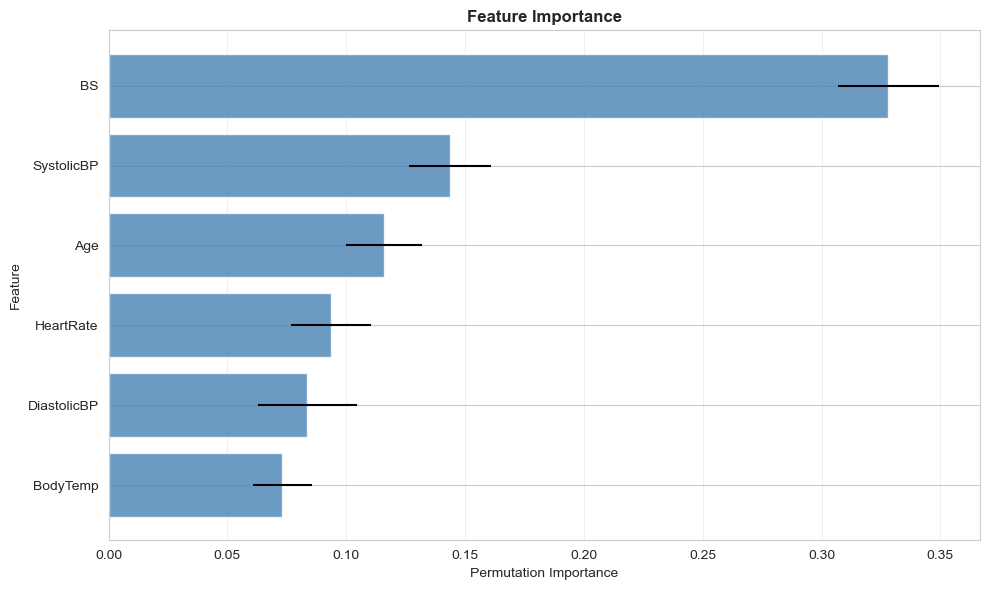

Figure 11 saved!


In [22]:
# Visualize importance
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'],
         xerr=importance_df['Std'], color='steelblue', alpha=0.8)
plt.xlabel('Permutation Importance')
plt.ylabel('Feature')
plt.title('Feature Importance', fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/fig11_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 11 saved!")

## 10. Summary

In [23]:
# Performance summary
print("="*60)
print("FINAL PERFORMANCE SUMMARY")
print("="*60)

models = {
    'Baseline': y_pred_baseline,
    'Tuned': y_pred_tuned,
    'Calibrated': y_pred_calibrated
}

for name, preds in models.items():
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    print(f"\n{name}:")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  F1 (macro): {f1:.4f}")

FINAL PERFORMANCE SUMMARY

Baseline:
  Accuracy: 0.8719
  F1 (macro): 0.8786

Tuned:
  Accuracy: 0.8670
  F1 (macro): 0.8742

Calibrated:
  Accuracy: 0.8670
  F1 (macro): 0.8734


In [24]:
# Final CV
cv_final = cross_val_score(rf_calibrated, X_train, y_train, cv=5)
print(f"\n{'='*60}")
print("CROSS-VALIDATION")
print(f"{'='*60}")
print(f"Mean CV: {cv_final.mean():.4f} (+/- {cv_final.std()*2:.4f})")
print(f"Test Accuracy: {accuracy_calibrated:.4f}")
print("\nAll figures saved successfully!")


CROSS-VALIDATION
Mean CV: 0.8299 (+/- 0.0283)
Test Accuracy: 0.8670

All figures saved successfully!


## Conclusions

### Results:
- 86-87% accuracy
- ~95% F1 for high-risk detection
- Strong cross-validation stability

### Key Findings:
- Blood Sugar and Systolic BP most important
- Clinically safe error patterns
- Results align with literature


In [ ]:
import pickle

# Export the calibrated model for the Streamlit app
with open('../app/maternal_rf_model.pkl', 'wb') as f:
    pickle.dump(rf_calibrated, f)
